In [130]:
#import des bibliothèques 
import pandas as pd
import numpy as np 
from scipy.spatial.transform import Rotation
from pathlib import Path
import matplotlib.pyplot as plt

In [131]:
#import des données 
lat_col = "latitude"
lon_col="longitude"
time_col="timestamp"

In [132]:
#calcul de la distance entre deux points 
def haversine(lat1,lon1,lat2,lon2):
    R=6371000
    
    lat1=np.radians(lat1)
    lon1=np.radians(lon1)
    lat2=np.radians(lat2)
    lon2=np.radians(lon2)
    
    dlat=lat2-lat1
    dlon=lon2-lon1
    
    a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)
    
    return 2*R*np.arcsin(np.sqrt(a))


In [133]:
def remove_gnss_aberrant(df,lat_col="latitude",lon_col="longitude",seuil_grand=30,seuil_petit=10):
    """Supprime les points GNSS aberrants"""
    
    df=df.copy()
    #shift(1) point précédent 
    #shift(-1) point suivant
    
    df = df[(df[lat_col].between(-90, 90)) & (df[lon_col].between(-180, 180))]
    
    #Calcul de la distance entre le point préédent et le point courant
    df["d_prev"]=haversine(df[lat_col].shift(1),
                          df[lon_col].shift(1),
                          df[lat_col],
                          df[lon_col])
    
    #Calcul de la distance entre le point courant et le point suivant
    df["d_next"]=haversine(df[lat_col],
                          df[lon_col],
                          df[lat_col].shift(-1),
                          df[lon_col].shift(-1))
    
    #Calcul de la distance entre le point préédent et le point suivant
    df["d_skip"]=haversine(df[lat_col].shift(1),
                          df[lon_col].shift(1),
                          df[lat_col].shift(-1),
                          df[lon_col].shift(-1))
    
    #on ajoute une colonne pour savoir si le point courant est abberant ou non 
    df["est_aberrant"] = (
        (df["d_prev"] > seuil_grand)
        & (df["d_next"] > seuil_grand)
        & (df["d_skip"] < seuil_petit)
    )
    
    print("Nombre de points total :", len(df))
    print("Nombre de points aberrants détectés :", df["est_aberrant"].sum())
    
    return df[df["est_aberrant"]==False].copy()

In [134]:
def remove_gnss_aberrant_zone(df,lat_col="latitude",lon_col="longitude",rayon_max=500):
    """supprime les points GNSS abbrrant mais par zone """
    df = df.copy()

    df = df[df[lat_col].between(-90, 90) & df[lon_col].between(-180, 180)].copy()

    #Repère de notre trajet 
    lat_ref = df[lat_col].median()
    lon_ref = df[lon_col].median()

    #distance de chaque point au centre du trajet
    df["distance_centre"] = haversine(lat_ref,lon_ref,df[lat_col],df[lon_col])

    df["est_aberrant_zone"] = df["distance_centre"] > rayon_max

    print("Centre estimé :", lat_ref, lon_ref)
    print("Points initiaux :", len(df))
    print("Points hors zone :", df["est_aberrant_zone"].sum())

    return df[df["est_aberrant_zone"] == False].copy()

In [135]:
R_EARTH=6371000
def latlon_to_xy(lat,lon,lat0,lon0):
    lat=np.asarray(lat)
    lon=np.asarray(lon)
    
    x=np.radians(lon-lon0)*R_EARTH*np.cos(np.radians(lat0))
    y=np.radians(lat-lat0)*R_EARTH
    return x,y

In [136]:
def xy_to_latlon(x,y,lat0,lon0):
    lat=lat0+np.degrees(y/R_EARTH)
    lon=lon0+np.degrees(x/(R_EARTH*np.cos(np.radians(lat0))))
    return lat,lon

In [141]:
def remettre_angle_entre_moins_pi_et_pi(angle):
    while angle > np.pi:
        angle = angle - 2 * np.pi

    while angle < -np.pi:
        angle = angle + 2 * np.pi

    return angle

In [142]:
def cap_initial_magnetique(mag_df):
    """Retourne le cap initial à partir de la 1er valeur du magnétomètre."""
    mx = mag_df["mag_x"].iloc[0]
    my = mag_df["mag_y"].iloc[0]
    return np.arctan2(my, mx)

In [143]:
def calibration_multi_immobile(gnss_files, imu_files, ma):
    biais_ax = []
    biais_ay = []
    biais_gz = []

    var_ax = []
    var_ay = []
    var_gz = []

    var_gps_x = []
    var_gps_y = []

    caps_initiaux = []

    for gnss_file, imu_file, mag_file in zip(gnss_files, imu_files, mag_files):

        imu = pd.read_csv(imu_file)
        gnss = pd.read_csv(gnss_file)
        mag = pd.read_csv(mag_file)

        # biais IMU = moyenne de chaque acquisition immobile
        biais_ax.append(imu["accel_x"].mean())
        biais_ay.append(imu["accel_y"].mean())
        biais_gz.append(np.radians(imu["gyro_z"]).mean())

        # Bruit IMU (= variance
        var_ax.append(imu["accel_x"].var())
        var_ay.append(imu["accel_y"].var())
        var_gz.append(np.radians(imu["gyro_z"]).var())

        # Bruit GPS statique
        lat0 = gnss["latitude"].mean()
        lon0 = gnss["longitude"].mean()

        x, y = latlon_to_xy(gnss["latitude"], gnss["longitude"],lat0,lon0)

        var_gps_x.append(np.var(x))
        var_gps_y.append(np.var(y))

        # Extraction du cap initial pour le magnétomètre
        if len(mag) > 0 and "mag_x" in mag.columns and "mag_y" in mag.columns:
            caps_initiaux.append(cap_initial_magnetique(mag))
        else:
            print("Fichier magnéto vide ou invalide :", mag_file)

        
    # Calcul des moyennes globales des biais
    biais = {
            "accel_x": np.mean(biais_ax),
            "accel_y": np.mean(biais_ay),
            "gyro_z": np.mean(biais_gz)}

    # Calcul du dt moyen sur le premier fichier IMU pour dimensionner Q
    dt_moyen = np.diff(pd.read_csv(imu_files[0])["timestamp"]).mean()

    var_accel = max(np.mean(var_ax), np.mean(var_ay))
    var_gyro = np.mean(var_gz)

    # Construction de la matrice Q
    Q = np.diag([
            0.05,
            0.05,
            var_accel * dt_moyen**2,
            var_accel * dt_moyen**2,
            var_gyro * dt_moyen**2])
    

    # Matrice R_gps basée sur l'immobilité (sécurité minimale à 2.5m de sigma)
    R_gps = np.diag([
        np.mean(var_gps_x),
        np.mean(var_gps_y)])

    # Matrice R_mag pour le cap du magnétomètre
    R_mag = np.array([[np.radians(25.0) ** 2]])

    print("Résultats de la Calibration Multi-Immobile")
    print(f"Biais accel_x : {biais['accel_x']:.4f}")
    print(f"Biais accel_y : {biais['accel_y']:.4f}")
    print(f"Biais gyro_z deg/s : {np.degrees(biais['gyro_z']):.4f}")
    print(f"R_gps sigma x/y : {np.sqrt(R_gps[0,0]):.2f} m, {np.sqrt(R_gps[1,1]):.2f} m")
    print(f"R_mag sigma deg : {np.degrees(np.sqrt(R_mag[0,0])):.2f}°")

    return Q, R_gps, biais, caps_initiaux

In [318]:
def kalman_gnss_imu(df, Q, R_gps_base, biais, cap_mag_init):
    df = df.sort_values("timestamp").copy()
    temps = df["timestamp"].to_numpy()
    gnss_valid=df["gnss_valid"].to_numpy()
    dt = np.diff(temps, prepend=temps[0])
    dt[dt <= 0] = 0.1
    dt[dt > 1.0] = 1.0
    
    latitudes = df["latitude"].to_numpy()
    longitudes = df["longitude"].to_numpy()
    hdops = df["hdop"].to_numpy() 

    lat0, lon0 = latitudes[0], longitudes[0]
    gps_x, gps_y = latlon_to_xy(df["latitude"], df["longitude"], lat0, lon0)

    accel_x_tel = df["accel_x"].to_numpy()
    accel_y_tel = df["accel_y"].to_numpy()
    accel_z_tel = df["accel_z"].to_numpy()
    gyro_z = np.radians(df["gyro_z"].to_numpy())

    
    H_gps = np.array([
        [1, 0, 0, 0, 0],
        [0, 1, 0, 0, 0]
    ])
    
    if len(gps_x) > 1 and dt[1] > 0:
        vx_init = np.clip((gps_x[1] - gps_x[0]) / dt[1], -5.0, 5.0)
        vy_init = np.clip((gps_y[1] - gps_y[0]) / dt[1], -5.0, 5.0)
    else:
        vx_init, vy_init = 0.0, 0.0

    # État initial
    etat = np.array([gps_x[0], gps_y[0], vx_init, vy_init, cap_mag_init])
    P   = np.diag([R_gps_base[0, 0], R_gps_base[1, 1], 1.0, 1.0, 1.0])


    etats_sauvegardes = []

    for k in range(len(df)):
        position_x = etat[0]
        position_y = etat[1]
        vitesse_x = etat[2]
        vitesse_y = etat[3]
        theta = etat[4]
        dtk = dt[k]

        # Rotation plaque ->monde
        R_rot = Rotation.from_euler('z', theta)
        accel_x_tel_corr = accel_x_tel[k] - biais["accel_x"]
        accel_y_tel_corr = accel_y_tel[k] - biais["accel_y"]
        gyro_z_corr = gyro_z[k] - biais["gyro_z"]
        
        accel_monde = R_rot.apply([accel_x_tel_corr, accel_y_tel_corr, accel_z_tel[k]])
        
        #accélération mesurée dans le repère téléphone vers le répère monde
        accel_x = accel_monde[0]
        accel_y = accel_monde[1]
        
        #ici je suppose que la  vitesse est la même entre deux mesures GPS
        #accel_x = 0
        #accel_y = 0

        #prediction
        etat_predit = etat.copy()
        etat_predit[0] = position_x + vitesse_x * dtk + 0.5 * accel_x * dtk**2
        etat_predit[1] = position_y + vitesse_y * dtk + 0.5 * accel_y * dtk**2
        etat_predit[2] = vitesse_x + accel_x * dtk
        etat_predit[3] = vitesse_y + accel_y * dtk
        
        etat_predit[4] = theta + gyro_z_corr * dtk
        etat_predit[4] = remettre_angle_entre_moins_pi_et_pi(etat_predit[4])
        
        # matrice F
        F = np.eye(5)
        F[0, 2] = dtk  # x dépend de vx
        F[1, 3] = dtk  # y dépend de vy

        P_predit = F @ P @ F.T + Q 

        # corrcetion gps
        mesure_gps = np.array([gps_x[k], gps_y[k]])
        erreur_gps = mesure_gps - H_gps @ etat_predit


        if gnss_valid[k] == 1:
            hdop_effectif = hdops[k]
        else:
            hdop_effectif = 2

        R_gps_dynamique = R_gps_base * 40 * hdop_effectif**2

        S = H_gps @ P_predit @ H_gps.T + R_gps_dynamique
        K = P_predit @ H_gps.T @ np.linalg.inv(S)

        etat_predit = etat_predit + K @ erreur_gps
        P_predit = (np.eye(5) - K @ H_gps) @ P_predit

        # enregistrement
        etat = etat_predit
        P = P_predit
        etats_sauvegardes.append(etat.copy())

    etats_sauvegardes = np.asarray(etats_sauvegardes)
    sortie = df.copy()
    
    lat_kalman, lon_kalman = xy_to_latlon(etats_sauvegardes[:, 0], etats_sauvegardes[:, 1], lat0, lon0)
    sortie["latitude"] = lat_kalman
    sortie["longitude"] = lon_kalman

    return sortie

# 1) Mettre le CSV avec les données synchronisées dans csv_path

In [419]:
#A remplir 
csv_path = Path("test2.csv")

In [420]:
#les résultats seront enregistrés dans ce dossier 
out_dir = Path("kalman_outputs")
out_dir.mkdir(parents=True, exist_ok=True)

In [421]:
df = pd.read_csv(csv_path)
print("Points initiaux :", len(df))
df.head()

Points initiaux : 3297


,timestamp,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,mag_x,mag_y,mag_z,latitude,longitude,hdop,pdop,vdop,gnss_valid
0,1.779288e+09,0.962641,-0.036112,0.129442,0.194586,19.725358,20.492928,-0.603917,0.276527,0.54297,49.384155,1.069913,1.3,2.1,1.6,1
1,1.779288e+09,1.044320,-0.067222,0.182695,0.824586,19.436608,14.254178,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0
2,1.779288e+09,0.975939,-0.019886,0.044164,4.009586,-88.345892,-64.933322,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0
3,1.779288e+09,0.724558,0.141642,-0.065331,-0.811664,-71.020892,-50.382072,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0
4,1.779288e+09,0.929030,0.100101,-0.039528,-1.852914,12.454108,17.377928,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0


### On retire les points aberrants de notre jeu de données

In [422]:
clean = remove_gnss_aberrant_zone(df, rayon_max=500)
print("Points après nettoyage :", len(clean))
clean.head()

Centre estimé : 49.38506683333333 1.070196666666667
Points initiaux : 3297
Points hors zone : 7
Points après nettoyage : 3290


,timestamp,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,mag_x,mag_y,mag_z,latitude,longitude,hdop,pdop,vdop,gnss_valid,distance_centre,est_aberrant_zone
0,1.779288e+09,0.962641,-0.036112,0.129442,0.194586,19.725358,20.492928,-0.603917,0.276527,0.54297,49.384155,1.069913,1.3,2.1,1.6,1,103.442336,False
1,1.779288e+09,1.044320,-0.067222,0.182695,0.824586,19.436608,14.254178,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0,103.442336,False
2,1.779288e+09,0.975939,-0.019886,0.044164,4.009586,-88.345892,-64.933322,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0,103.442336,False
3,1.779288e+09,0.724558,0.141642,-0.065331,-0.811664,-71.020892,-50.382072,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0,103.442336,False
4,1.779288e+09,0.929030,0.100101,-0.039528,-1.852914,12.454108,17.377928,-0.603917,0.276527,0.54297,49.384155,1.069913,NaN,NaN,NaN,0,103.442336,False


### Enregistrement des données sans points abberrants

In [423]:
clean.to_csv(out_dir / "synced_imu_gnss_clean.csv", index=False)
res.to_csv(out_dir / "kalman_result.csv", index=False)

print("CSV sauvegardés dans :", out_dir)

CSV sauvegardés dans : kalman_outputs


### Initialisation des biais et cap initial et application de Kalman

In [424]:
gnss_files = [
    "imo/imo1/gnss.csv",
    "imo/imo2/gnss.csv",
    "imo/imo3/gnss.csv",
    "imo/imo4/gnss.csv",
    "imo/imo5/gnss.csv",
    "imo/imo5/gnss.csv"
]

imu_files = [
    "imo/imo1/imu.csv",
    "imo/imo2/imu.csv",
    "imo/imo3/imu.csv",
    "imo/imo4/imu.csv",
    "imo/imo5/imu.csv",
    "imo/imo6/imu.csv",  
]

mag_files = [
    "imo/imo1/magnéto.csv",
    "imo/imo2/magnéto.csv",
    "imo/imo3/magnéto.csv",
    "imo/imo4/magnéto.csv",
    "imo/imo5/magnéto.csv",
    "imo/imo6/magnéto.csv"
]

Q, R_gps, biais , caps_initiaux = calibration_multi_immobile(
    gnss_files,
    imu_files,
    mag_files)

cap_init = np.arctan2(
    np.mean(np.sin(caps_initiaux)),
    np.mean(np.cos(caps_initiaux)))


res = kalman_gnss_imu(clean, Q, R_gps, biais, cap_init)

Résultats de la Calibration Multi-Immobile
Biais accel_x : 0.9719
Biais accel_y : -0.0246
Biais gyro_z deg/s : 0.0501
R_gps sigma x/y : 1.19 m, 2.26 m
R_mag sigma deg : 25.00°


### Affichage de la trajectoire GNSS clean et de la trajectoire avec Kalman

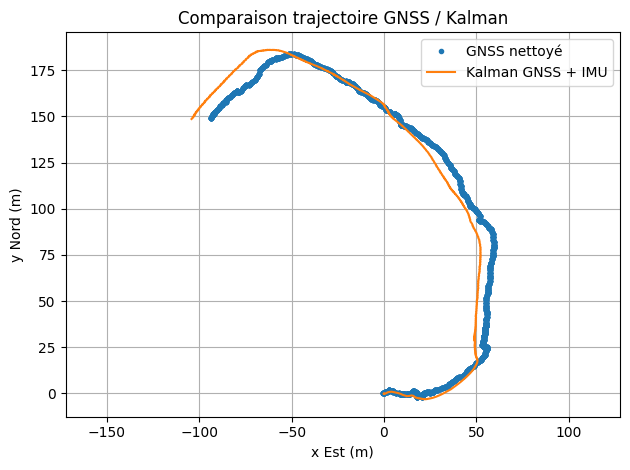

In [425]:
lat0 = clean["latitude"].to_numpy()[0]
lon0 = clean["longitude"].to_numpy()[0]

x_gnss, y_gnss = latlon_to_xy(
    clean["latitude"],
    clean["longitude"],
    lat0,
    lon0)

x_kalman, y_kalman = latlon_to_xy(
    res["latitude"],
    res["longitude"],
    lat0,
    lon0)

plt.plot(x_gnss, y_gnss, ".", label="GNSS nettoyé")
plt.plot(x_kalman, y_kalman, "-", label="Kalman GNSS + IMU")

plt.axis("equal")
plt.xlabel("x Est (m)")
plt.ylabel("y Nord (m)")
plt.title("Comparaison trajectoire GNSS / Kalman")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(out_dir / "comparaison_trajectoire.png", dpi=200)
plt.show()

### Applicatin du filtre de Savitzky-Golay

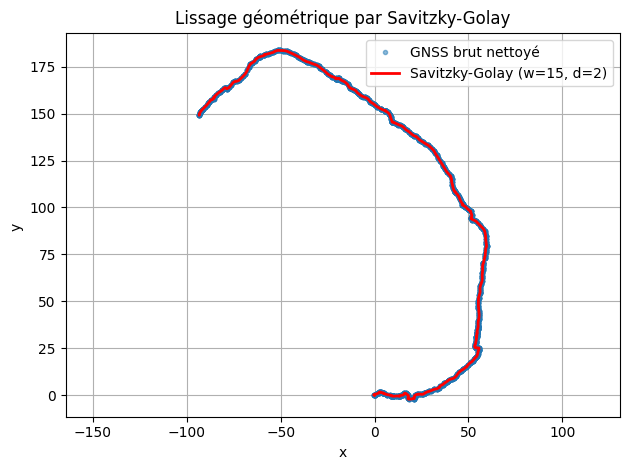

In [426]:
from scipy.signal import savgol_filter

#Extraction des coordonnées locales issues du GPS nettoyé
lat0 = clean["latitude"].to_numpy()[0]
lon0 = clean["longitude"].to_numpy()[0]

x_gnss, y_gnss = latlon_to_xy(clean["latitude"],clean["longitude"],lat0,lon0)


# window_length : Nombre de points de la fenêtre Plus il est grand, plus c'est lisse
# polyorder : Degré du polynôme à ajuster ici 2 car il respecte les paraboles pour les virages
window = 15
degre = 2

x_savgol = savgol_filter(x_gnss, window_length=window, polyorder=degre)
y_savgol = savgol_filter(y_gnss, window_length=window, polyorder=degre)

#Reconversion des coordonnées lissées en Latitude / Longitude
lat_savgol, lon_savgol = xy_to_latlon(x_savgol, y_savgol, lat0, lon0)

#sauvegarde
df_savgol = clean.copy()
df_savgol["latitude"] = lat_savgol
df_savgol["longitude"] = lon_savgol
df_savgol.to_csv(out_dir / "savgol_result.csv", index=False)

# Affichage du graphique de comparaison
plt.plot(x_gnss, y_gnss, ".", label="GNSS brut nettoyé", alpha=0.5)
plt.plot(x_savgol, y_savgol, "-", label=f"Savitzky-Golay (w={window}, d={degre})", linewidth=2, color="red")

plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y ")
plt.title("Lissage géométrique par Savitzky-Golay")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Effet de la correction du biais 

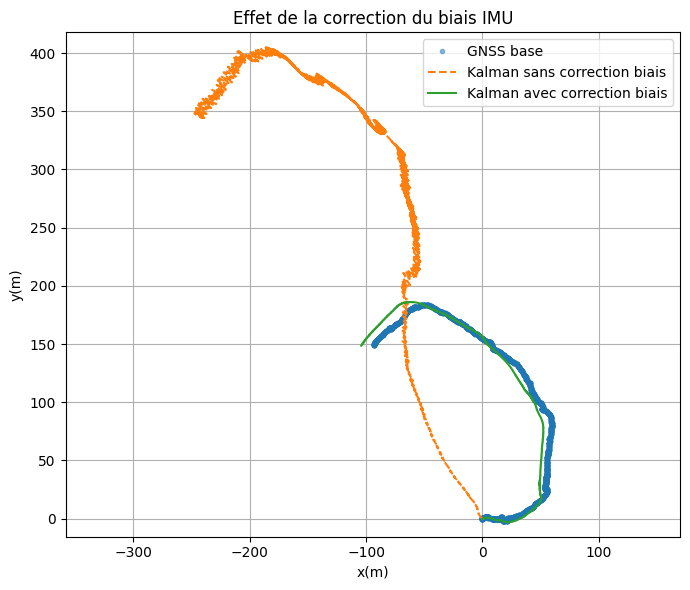

In [427]:
biais_zero = {
    "accel_x": 0,
    "accel_y": 0,
    "gyro_z": 0
}

res_sans_biais = kalman_gnss_imu(clean, Q, R_gps, biais_zero, cap_init)
res_avec_biais = kalman_gnss_imu(clean, Q, R_gps, biais, cap_init)

x_gnss, y_gnss = latlon_to_xy(clean["latitude"], clean["longitude"], lat0, lon0)
x_sans, y_sans = latlon_to_xy(res_sans_biais["latitude"], res_sans_biais["longitude"], lat0, lon0)
x_avec, y_avec = latlon_to_xy(res_avec_biais["latitude"], res_avec_biais["longitude"], lat0, lon0)

plt.figure(figsize=(7,6))
plt.plot(x_gnss, y_gnss, ".", label="GNSS base", alpha=0.5)
plt.plot(x_sans, y_sans, "--", label="Kalman sans correction biais")
plt.plot(x_avec, y_avec, "-", label="Kalman avec correction biais")
plt.axis("equal")
plt.xlabel("x(m)")
plt.ylabel("y(m)")
plt.title("Effet de la correction du biais IMU")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Analyse de sensibilité sur le HDOP

In [428]:
def analyse_sensibilite_hdop(
    clean,
    Q,
    R_gps,
    biais,
    cap_init,
    facteurs_hdop=[0.5, 1, 2, 5],
):
    resultats = {}

    lat0 = clean["latitude"].iloc[0]
    lon0 = clean["longitude"].iloc[0]

    x_gnss, y_gnss = latlon_to_xy(
        clean["latitude"], clean["longitude"], lat0, lon0
    )

    for facteur in facteurs_hdop:
        df_test = clean.copy()

        df_test.loc[df_test["gnss_valid"] == 1, "hdop"] = (
            df_test.loc[df_test["gnss_valid"] == 1, "hdop"] * facteur
        )

        res_test = kalman_gnss_imu(
            df_test,
            Q,
            R_gps,
            biais,
            cap_init
        )

        hdop_valides = df_test.loc[df_test["gnss_valid"] == 1, "hdop"]
        facteur_R_moyen = (40 * hdop_valides**2).mean()

        print(f"HDOP × {facteur}")
        print(f"  HDOP moyen modifié   : {hdop_valides.mean():.3f}")
        print(f"  facteur R_gps moyen : {facteur_R_moyen:.3f}")
        print()

        resultats[facteur] = res_test

    plt.figure(figsize=(8, 6))
    plt.plot(x_gnss, y_gnss, ".", alpha=0.35, label="GNSS nettoyé")

    for facteur, res_test in resultats.items():
        x_kalman, y_kalman = latlon_to_xy(
            res_test["latitude"], res_test["longitude"], lat0, lon0
        )
        plt.plot(x_kalman, y_kalman, linewidth=2, label=f"Kalman HDOP × {facteur}")

    plt.axis("equal")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Influence du HDOP sur la trajectoire estimée")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return resultats


HDOP × 0.1
  HDOP moyen modifié   : 0.105
  facteur R_gps moyen : 0.448

HDOP × 1
  HDOP moyen modifié   : 1.053
  facteur R_gps moyen : 44.830

HDOP × 10
  HDOP moyen modifié   : 10.534
  facteur R_gps moyen : 4482.955

HDOP × 50
  HDOP moyen modifié   : 52.670
  facteur R_gps moyen : 112073.864

HDOP × 100
  HDOP moyen modifié   : 105.341
  facteur R_gps moyen : 448295.455



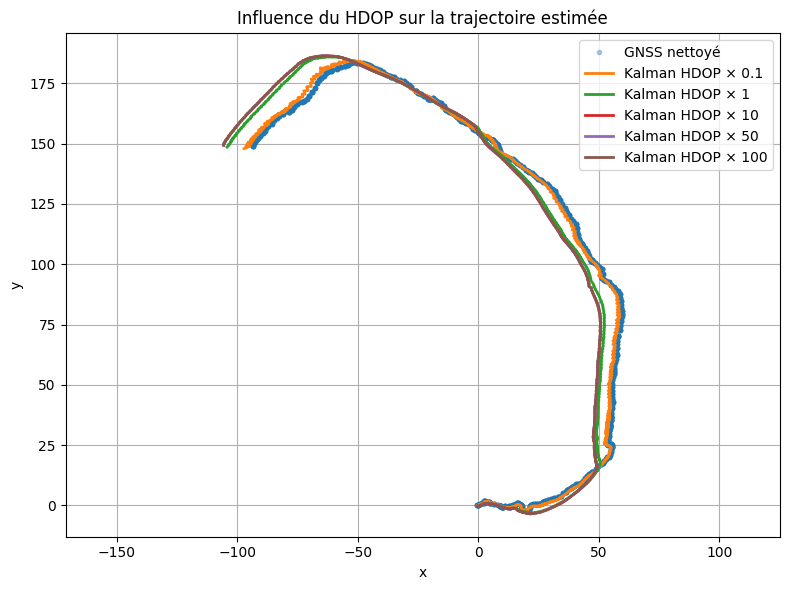

In [429]:
resultats_hdop = analyse_sensibilite_hdop(
    clean=clean,
    Q=Q,
    R_gps=R_gps,
    biais=biais,
    cap_init=cap_init,
    facteurs_hdop=[0.1, 1, 10, 50, 100]
)

### Analyse/ Comparaison 

## 2) Changer le gpx_file pour réaliser la comparaison avec strava

In [430]:
from conversion_gpx import convert_gpx_to_csv

convert_gpx_to_csv(gpx_file="test2.gpx",csv_file="strava.csv")
strava_csv = "strava.csv"

Conversion terminée ! Fichier enregistré : strava.csv


In [431]:
def preparer_strava(strava_csv, lat0, lon0):
    strava = pd.read_csv(strava_csv)

    strava["x"],strava["y"] = latlon_to_xy(strava["Latitude"],strava["Longitude"],lat0,lon0)

    return strava

In [432]:
def distance_cumulee(x, y):
    dx= np.diff(x, prepend=x[0])
    dy = np.diff(y, prepend=y[0])
    d = np.sqrt(dx**2 + dy**2)
    return np.cumsum(d)

def preparer_xy(df, lat_col="latitude", lon_col="longitude"):
    lat0 =df[lat_col].iloc[0]
    lon0= df[lon_col].iloc[0]

    x, y = latlon_to_xy(df[lat_col],df[lon_col],lat0,lon0)
    return np.asarray(x), np.asarray(y)

def comparer_strava_simple(strava_csv, trajectoires):
    # Lecture csv Strava
    strava= pd.read_csv(strava_csv)

    # conversion Strava en x/y
    x_ref,y_ref = preparer_xy(strava,lat_col="Latitude",lon_col="Longitude")

    # Distance cumulée Strava
    s_ref= distance_cumulee(x_ref, y_ref)

    # Avancement normalisé entre 0 et 1
    u_ref = s_ref / s_ref[-1]

    stats =[]

    plt.figure(figsize=(8, 6))
    plt.plot(x_ref, y_ref, label="Strava", linewidth=2)

    for nom, df in trajectoires.items():

        x,y = preparer_xy(df)

        s =distance_cumulee(x, y)
        u = s / s[-1]

        # on echantillonne la trajectoire test aux mêmes avancements que Strava
        x_interp =np.interp(u_ref, u, x)
        y_interp = np.interp(u_ref, u, y)

        erreur =np.sqrt((x_interp - x_ref)**2 + (y_interp - y_ref)**2)

        stats.append({
            "Méthode": nom,
            "Erreur moyenne (m)": erreur.mean(),
            "Erreur médiane (m)": np.median(erreur),
            "RMSE (m)": np.sqrt(np.mean(erreur**2)),
            "Erreur max (m)": erreur.max()
        })

        plt.plot(x_interp,y_interp, label=nom)

    plt.axis("equal")
    plt.xlabel("x(m)")
    plt.ylabel("y (m)")
    plt.title("Comparaison des trajectoires avec Strava")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(stats)

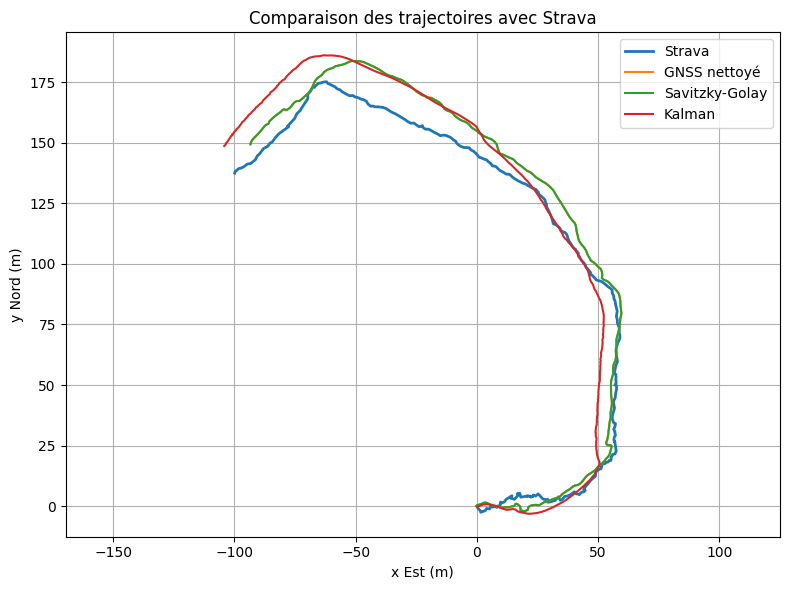

,Méthode,Erreur moyenne (m),Erreur médiane (m),RMSE (m),Erreur max (m)
0,GNSS nettoyé,9.621544,10.002498,10.102900,15.122999
1,Savitzky-Golay,9.063402,9.121348,9.591953,15.175298
2,Kalman,18.016382,20.879395,18.806212,23.819995


In [433]:
tableau_stats = comparer_strava_simple(
    strava_csv,
    {
        "GNSS nettoyé": clean,
        "Savitzky-Golay": df_savgol,
        "Kalman": res
    }
)

tableau_stats